In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from collections import Counter

from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load the 20 Newsgroups dataset

categories = [
    'comp.graphics',
    'rec.sport.baseball',
    'sci.space',
    'talk.politics.misc'
]

dataset = fetch_20newsgroups(
    subset='all',
    categories=categories,
    remove=('headers', 'footers', 'quotes')
)

df = pd.DataFrame({
    'text': dataset.data,
    'label': dataset.target
})

df['category'] = df['label'].map(
    dict(enumerate(dataset.target_names))
)

print("Dataset loaded successfully!")
print("Total documents:", len(df))
print("Total categories:", len(dataset.target_names))

df.head()

Dataset loaded successfully!
Total documents: 3729
Total categories: 4


,text,label,category
0,\nAre you kidding? I'm stuck with the Toronto...,1,rec.sport.baseball
1,\n\n\n\n\n\nSigh. You're absolutely right. W...,3,talk.politics.misc
2,\n\n The above statement ignores reality. The ...,3,talk.politics.misc
3,\nI'm sorry about your friend. Really. But t...,3,talk.politics.misc
4,Hank Greenberg was probably the greatest ever....,1,rec.sport.baseball


In [3]:
# Display dataset information

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nCategory distribution:")
print(df['category'].value_counts())

print("\nSample news article:")
print(df['text'].iloc[0][:1000])

Dataset shape: (3729, 3)

Missing values:
text        0
label       0
category    0
dtype: int64

Category distribution:
category
rec.sport.baseball    994
sci.space             987
comp.graphics         973
talk.politics.misc    775
Name: count, dtype: int64

Sample news article:

Are you kidding?  I'm stuck with the Toronto SkyDome, where their idea
of a 7th inning stretch is that "Blue Jays" song where everyone gets
to yell:  "Okay, okay, Blue Jays, Blue Jays, Let's Play Ball!"

Wow.. what genius did it take to compose that one, to outshine the
old classic.  And there are women on the field to "lead the crowd".


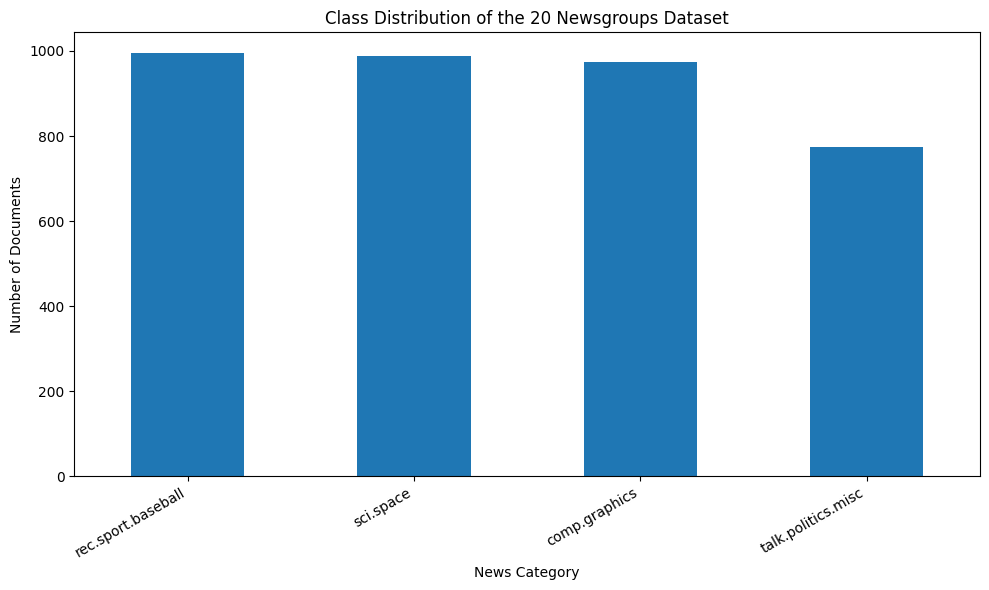

In [4]:
# Visualize the number of documents in each category

class_counts = df['category'].value_counts()

plt.figure(figsize=(10, 6))

class_counts.plot(kind='bar')

plt.title('Class Distribution of the 20 Newsgroups Dataset')
plt.xlabel('News Category')
plt.ylabel('Number of Documents')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()

plt.savefig(
    'class_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [5]:
# Separate input text and target labels

X = df['text']
y = df['label']

print("Total text samples:", len(X))
print("Total labels:", len(y))

print("\nLabel mapping:")

for i, category in enumerate(dataset.target_names):
    print(i, "=", category)

Total text samples: 3729
Total labels: 3729

Label mapping:
0 = comp.graphics
1 = rec.sport.baseball
2 = sci.space
3 = talk.politics.misc


In [6]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining category distribution:")
print(
    pd.Series(y_train)
    .map(dict(enumerate(dataset.target_names)))
    .value_counts()
)

print("\nTesting category distribution:")
print(
    pd.Series(y_test)
    .map(dict(enumerate(dataset.target_names)))
    .value_counts()
)

Training samples: 2983
Testing samples: 746

Training category distribution:
label
rec.sport.baseball    795
sci.space             790
comp.graphics         778
talk.politics.misc    620
Name: count, dtype: int64

Testing category distribution:
label
rec.sport.baseball    199
sci.space             197
comp.graphics         195
talk.politics.misc    155
Name: count, dtype: int64


In [7]:
# Convert text into numerical features using TF-IDF

vectorizer = TfidfVectorizer(
    stop_words='english',
    max_features=10000,
    ngram_range=(1, 1)
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("TF-IDF conversion completed!")

print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

print("Number of TF-IDF features:", len(vectorizer.get_feature_names_out()))

TF-IDF conversion completed!
Training matrix shape: (2983, 10000)
Testing matrix shape: (746, 10000)
Number of TF-IDF features: 10000


In [8]:
# Define the four classification algorithms

models = {
    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=5,
        metric='cosine',
        algorithm='brute'
    ),

    'SVM': LinearSVC(
        random_state=42
    ),

    'Naive Bayes': MultinomialNB()
}

print("Four models defined successfully!")

for name in models:
    print(name)

Four models defined successfully!
Decision Tree
KNN
SVM
Naive Bayes


In [9]:
# Train and evaluate all four models

results = []
predictions = {}

for name, model in models.items():

    print("Training:", name)

    # Measure training time
    start_time = time.perf_counter()

    model.fit(X_train_tfidf, y_train)

    training_time = time.perf_counter() - start_time

    # Measure testing time
    start_time = time.perf_counter()

    y_pred = model.predict(X_test_tfidf)

    testing_time = time.perf_counter() - start_time

    # Save predictions for later analysis
    predictions[name] = y_pred

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average='macro',
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average='macro',
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average='macro',
        zero_division=0
    )

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'Training Time (s)': training_time,
        'Testing Time (s)': testing_time
    })

    print("Accuracy:", round(accuracy, 4))
    print("F1-Score:", round(f1, 4))
    print()

# Create the original results table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='F1-Score',
    ascending=False
).reset_index(drop=True)

print("Original unigram model results:")
display(results_df)

Training: Decision Tree
Accuracy: 0.7306
F1-Score: 0.7257

Training: KNN
Accuracy: 0.8445
F1-Score: 0.8456

Training: SVM
Accuracy: 0.8874
F1-Score: 0.8873

Training: Naive Bayes
Accuracy: 0.9048
F1-Score: 0.9032

Original unigram model results:


,Model,Accuracy,Precision,Recall,F1-Score,Training Time (s),Testing Time (s)
0,Naive Bayes,0.904826,0.911705,0.900281,0.903173,0.007102,0.000890
1,SVM,0.887399,0.896253,0.884472,0.887273,0.078780,0.000951
2,KNN,0.844504,0.865510,0.840730,0.845606,0.006413,0.168653
3,Decision Tree,0.730563,0.732619,0.723847,0.725665,2.841903,0.005766


In [10]:
# Display a classification report for each model

for name, y_pred in predictions.items():

    print("=" * 65)
    print("Classification Report:", name)
    print("=" * 65)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=list(range(len(dataset.target_names))),
            target_names=dataset.target_names,
            zero_division=0
        )
    )

Classification Report: Decision Tree
                    precision    recall  f1-score   support

     comp.graphics       0.82      0.77      0.79       195
rec.sport.baseball       0.68      0.81      0.74       199
         sci.space       0.73      0.71      0.72       197
talk.politics.misc       0.71      0.61      0.65       155

          accuracy                           0.73       746
         macro avg       0.73      0.72      0.73       746
      weighted avg       0.73      0.73      0.73       746

Classification Report: KNN
                    precision    recall  f1-score   support

     comp.graphics       0.74      0.96      0.84       195
rec.sport.baseball       0.84      0.84      0.84       199
         sci.space       0.91      0.79      0.85       197
talk.politics.misc       0.97      0.77      0.86       155

          accuracy                           0.84       746
         macro avg       0.87      0.84      0.85       746
      weighted avg       0.86  

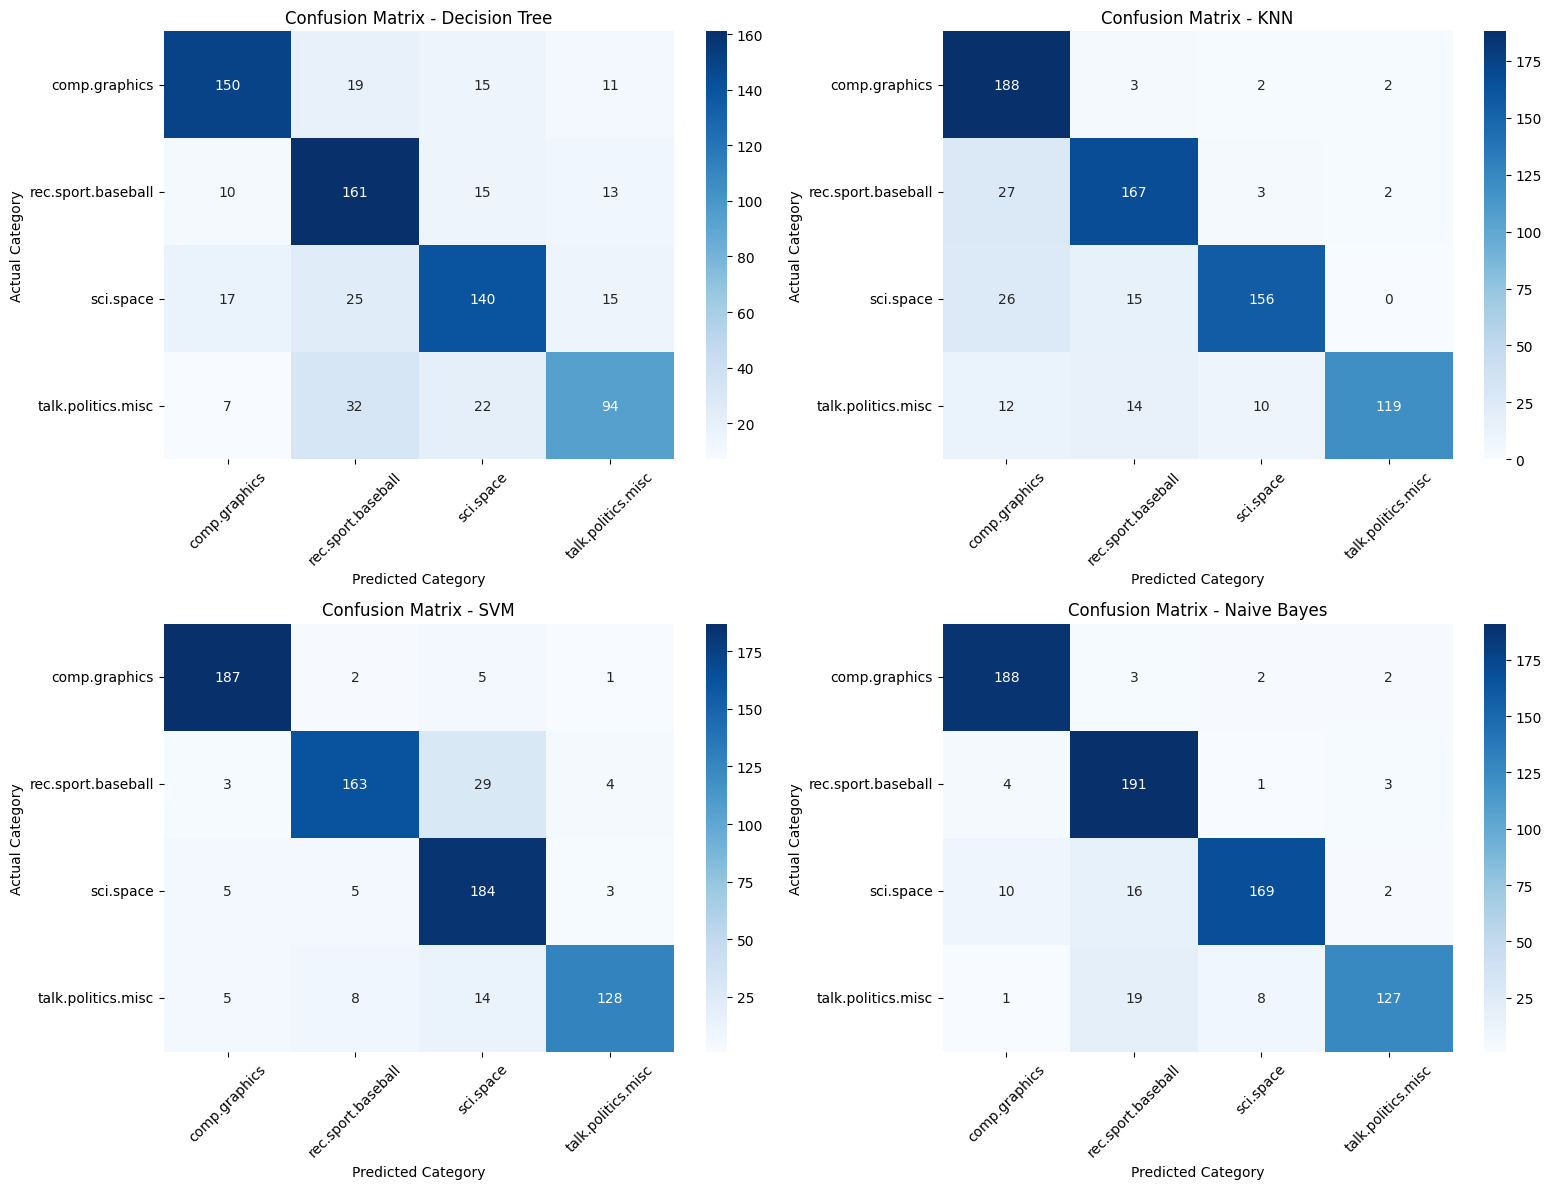

In [11]:
# Display all four confusion matrices in one figure

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 12)
)

axes = axes.flatten()

for ax, (name, y_pred) in zip(
    axes,
    predictions.items()
):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=list(range(len(dataset.target_names)))
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=dataset.target_names,
        yticklabels=dataset.target_names,
        ax=ax
    )

    ax.set_title(f'Confusion Matrix - {name}')
    ax.set_xlabel('Predicted Category')
    ax.set_ylabel('Actual Category')

    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)

plt.tight_layout()

plt.savefig(
    'confusion_matrix_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

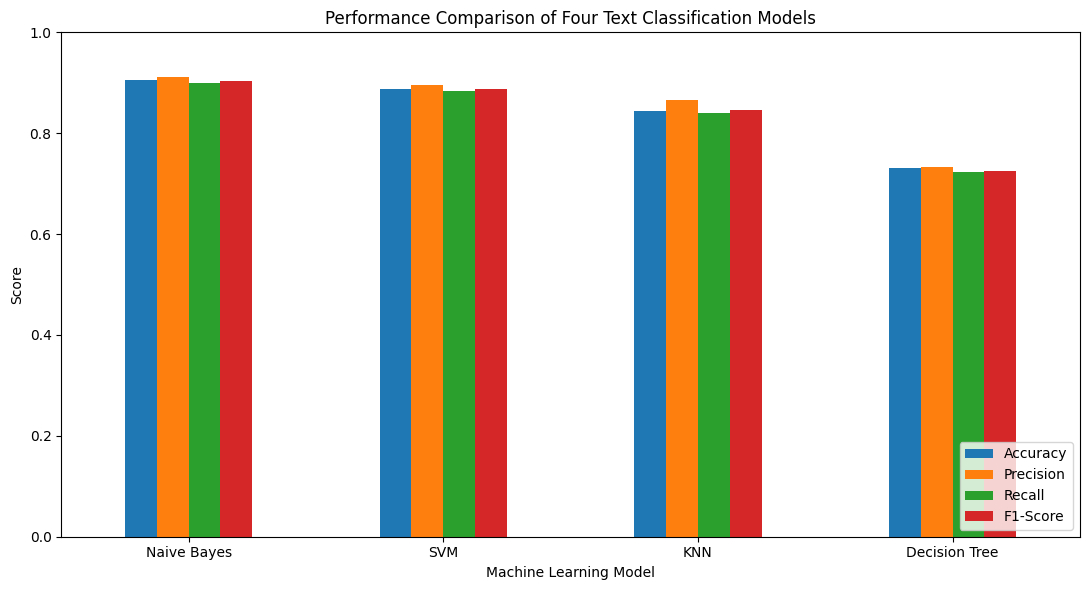

In [12]:
# Compare accuracy, precision, recall and F1-score

metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1-Score'
]

results_df.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(11, 6)
)

plt.title(
    'Performance Comparison of Four Text Classification Models'
)

plt.xlabel('Machine Learning Model')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()

plt.savefig(
    'model_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [13]:
# Identify the model with the highest macro F1-score

best_index = results_df['F1-Score'].idxmax()

best_model_name = results_df.loc[
    best_index,
    'Model'
]

best_f1 = results_df.loc[
    best_index,
    'F1-Score'
]

best_accuracy = results_df.loc[
    best_index,
    'Accuracy'
]

print("Best model based on macro F1-score:", best_model_name)

print("Accuracy:", round(best_accuracy, 4))

print("Macro F1-score:", round(best_f1, 4))

Best model based on macro F1-score: Naive Bayes
Accuracy: 0.9048
Macro F1-score: 0.9032


In [14]:
# What-if experiment: Compare unigram and unigram-plus-bigram TF-IDF

vectorizer_bigram = TfidfVectorizer(
    stop_words='english',
    max_features=10000,
    ngram_range=(1, 2)
)

X_train_bigram = vectorizer_bigram.fit_transform(X_train)
X_test_bigram = vectorizer_bigram.transform(X_test)

print("Bigram TF-IDF conversion completed!")

print("Training matrix shape:", X_train_bigram.shape)
print("Testing matrix shape:", X_test_bigram.shape)

Bigram TF-IDF conversion completed!
Training matrix shape: (2983, 10000)
Testing matrix shape: (746, 10000)


In [15]:
# Create separate models for the what-if experiment

bigram_models = {
    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=5,
        metric='cosine',
        algorithm='brute'
    ),

    'SVM': LinearSVC(
        random_state=42
    ),

    'Naive Bayes': MultinomialNB()
}

what_if_results = []

bigram_predictions = {}

for name, model in bigram_models.items():

    print("Training bigram model:", name)

    start_time = time.perf_counter()

    model.fit(X_train_bigram, y_train)

    training_time = time.perf_counter() - start_time

    y_pred = model.predict(X_test_bigram)

    bigram_predictions[name] = y_pred

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average='macro',
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average='macro',
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average='macro',
        zero_division=0
    )

    what_if_results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'Training Time (s)': training_time
    })

what_if_df = pd.DataFrame(what_if_results)

print("\nWhat-if experiment results:")
display(what_if_df)

Training bigram model: Decision Tree
Training bigram model: KNN
Training bigram model: SVM
Training bigram model: Naive Bayes

What-if experiment results:


,Model,Accuracy,Precision,Recall,F1-Score,Training Time (s)
0,Decision Tree,0.746649,0.751197,0.741178,0.743014,1.459249
1,KNN,0.837802,0.858569,0.833761,0.838144,0.002293
2,SVM,0.886059,0.893475,0.883546,0.885746,0.078592
3,Naive Bayes,0.904826,0.910894,0.900625,0.903397,0.006339


In [16]:
# Compare original and bigram F1-scores

comparison_df = results_df[
    ['Model', 'F1-Score']
].merge(
    what_if_df[['Model', 'F1-Score']],
    on='Model',
    suffixes=('_Unigram', '_Bigram')
)

comparison_df['F1 Change'] = (
    comparison_df['F1-Score_Bigram']
    - comparison_df['F1-Score_Unigram']
)

print("Unigram vs. Bigram comparison:")
display(comparison_df)

Unigram vs. Bigram comparison:


,Model,F1-Score_Unigram,F1-Score_Bigram,F1 Change
0,Naive Bayes,0.903173,0.903397,0.000224
1,SVM,0.887273,0.885746,-0.001526
2,KNN,0.845606,0.838144,-0.007462
3,Decision Tree,0.725665,0.743014,0.017349


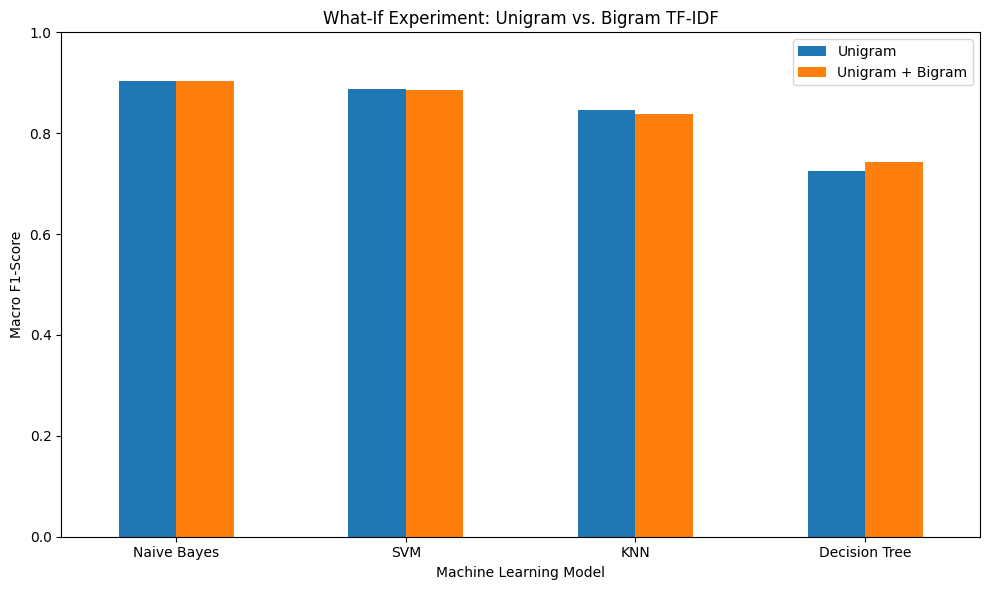

In [17]:
# Visualize the effect of adding bigrams

comparison_df.set_index('Model')[
    ['F1-Score_Unigram', 'F1-Score_Bigram']
].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('What-If Experiment: Unigram vs. Bigram TF-IDF')
plt.xlabel('Machine Learning Model')
plt.ylabel('Macro F1-Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(['Unigram', 'Unigram + Bigram'])
plt.tight_layout()

plt.savefig(
    'what_if_analysis.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [18]:
# Save the experimental results

results_df.to_csv(
    'results.csv',
    index=False
)

what_if_df.to_csv(
    'what_if_results.csv',
    index=False
)

comparison_df.to_csv(
    'what_if_comparison.csv',
    index=False
)

print("All result CSV files saved successfully!")

All result CSV files saved successfully!


In [19]:
# Generate a conclusion using actual experimental results

best_original = results_df.loc[
    results_df['F1-Score'].idxmax()
]

best_bigram = what_if_df.loc[
    what_if_df['F1-Score'].idxmax()
]

print("PROJECT CONCLUSION")
print("-" * 50)

print(
    f"The best model in the original unigram experiment "
    f"was {best_original['Model']}."
)

print(
    f"Its accuracy was {best_original['Accuracy']:.4f} "
    f"and its macro F1-score was "
    f"{best_original['F1-Score']:.4f}."
)

print(
    f"In the bigram experiment, the best model was "
    f"{best_bigram['Model']} with a macro F1-score of "
    f"{best_bigram['F1-Score']:.4f}."
)

print("\nF1-score changes after adding bigrams:")

for _, row in comparison_df.iterrows():

    change = row['F1 Change']

    if change > 0:
        result = "improved"
    elif change < 0:
        result = "decreased"
    else:
        result = "remained unchanged"

    print(
        f"{row['Model']}: {result} by {abs(change):.4f}"
    )

print(
    "\nThe results show how the four classifiers performed "
    "on this dataset. The preferred model should be selected "
    "based on the evaluation metrics and the classification "
    "errors observed in the confusion matrices."
)

PROJECT CONCLUSION
--------------------------------------------------
The best model in the original unigram experiment was Naive Bayes.
Its accuracy was 0.9048 and its macro F1-score was 0.9032.
In the bigram experiment, the best model was Naive Bayes with a macro F1-score of 0.9034.

F1-score changes after adding bigrams:
Naive Bayes: improved by 0.0002
SVM: decreased by 0.0015
KNN: decreased by 0.0075
Decision Tree: improved by 0.0173

The results show how the four classifiers performed on this dataset. The preferred model should be selected based on the evaluation metrics and the classification errors observed in the confusion matrices.


In [20]:
# Download the notebook's output files

from google.colab import files

output_files = [
    'class_distribution.png',
    'confusion_matrix_comparison.png',
    'model_comparison.png',
    'what_if_analysis.png',
    'results.csv',
    'what_if_results.csv',
    'what_if_comparison.csv'
]

for filename in output_files:
    files.download(filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>